Single allele groupped structue models.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
import logomaker
import sys
import seaborn as sns
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"


 1. Read data

In [2]:
DATA_PATH_BASE = 'G:/My Drive/Work/ITMO/data'
# DATA_PATH_BASE = 'D:/Google Drive/Work/ITMO/data' #windows
# DATA_PATH_BASE = '/home/denklewer/Data' #ubuntu

DATA_PATH = f'{DATA_PATH_BASE}/core_identification_paper/per_length_per_kfold_split/' # work laptop
TARGET_PATH_TO_RESULTS = "experiment_results/hp_a30_pc10_core_identification_paper/" #!CHANGE for bwv!

In [3]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = get_available_alleles(DATA_PATH)

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")
# per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
# per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonbinders")

sorted(ALLELES)

['HLA-A*01:01',
 'HLA-A*02:01',
 'HLA-A*03:01',
 'HLA-A*24:02',
 'HLA-B*07:02',
 'HLA-B*15:02',
 'HLA-B*27:05',
 'HLA-B*57:01',
 'HLA-C*12:02',
 'HLA-DRB1*01:01',
 'HLA-DRB1*04:01',
 'HLA-DRB1*04:04',
 'HLA-DRB1*07:01']

In [4]:
def make_logo_for_data(binders_array, name, ax=None):
    sns.set_theme(style="white")
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', flip_below=True, ax=ax)
    ww_logo.ax.set_title(f"{name}, {len(binders_array)}")

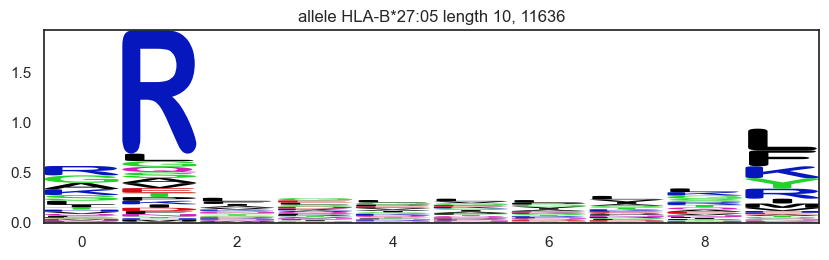

In [5]:
target_allele = ALLELES[0]
target_length = 10

binders_array = per_allele_per_kfold_per_length_binders_train[target_allele][0][target_length]
make_logo_for_data(binders_array, f"allele {target_allele} length {target_length}")

# 2. Prepare data and weithgs for training
## 2.1 Merge alleles into combinations and define params

In [21]:

# Training params
algorithm = 'viterbi'
combination_size = 1
TOTAL_SPLITS = 5
NUM_RUNS = 3
USE_WEIGHTS = False
check_peptides = True

target_class = "class2"

params = dict()


DataParams = {
"class1": {
    "ALLELES": sorted([ 'HLA-A*03:01']),
    "TARGET_LENGTHS":   [8, 9,10, 11, 12],
    'start_cycle': False,
    'end_cycle' :False,
    'intermediate_cycles' :True,
    'emission_pseudocount':50,
    'transition_pseudocount' : 0,
    'cycle_pseudocount' : 30,
    'anchor_top_aas':3,
    'anchor_default_pseudocount':50
},
    
"class2": {
    "ALLELES":sorted(['HLA-DRB1*01:01']),
    "TARGET_LENGTHS":    [12, 13,14, 15, 16,17, 18],
    'start_cycle': True,
    'end_cycle' : True,
    'intermediate_cycles' :False,
    'emission_pseudocount':10,
    'transition_pseudocount' : 1,
    'cycle_pseudocount' : 300,
    'anchor_top_aas':5,
    'anchor_default_pseudocount': 30
    
}

}




params['st'] = 14
params['alg'] = algorithm


params['min_iters'] = 30
params['max_iters'] = 90

params['emission_pseudocount'] = DataParams[target_class]["emission_pseudocount"]
params['transition_pseudocount'] =  DataParams[target_class]["transition_pseudocount"]
params['verbose'] = True
params['lr_decay'] = 0.0
params['edge_inertia'] = 0.5
params['distribution_inertia'] = 0.5
params['groups'] = 7
params['states_per_group'] = 2
params['model_complexity'] = 2
params['use_pseudocount'] = True

# Class 1 params
params['self_cycle'] = False
params['start_cycle'] = DataParams[target_class]["start_cycle"]
params['end_cycle'] =  DataParams[target_class]["end_cycle"]
params['equal_probs_for_cycle'] = False

params['freeze_distr'] = False # wether to freeze start and end cycle distributions
params['tie_cycle_states'] = False
params['cycle_pseudocount'] =  DataParams[target_class]["cycle_pseudocount"]
params['anchor_top_aas'] = DataParams[target_class]["anchor_top_aas"]
params['anchor_states'] = True
params['anchor_default_pseudocount'] =  DataParams[target_class]["anchor_default_pseudocount"]
params['tie_anchor_states'] = False
params['intermediate_cycles'] = DataParams[target_class]["intermediate_cycles"]
params['equal_probs_for_intermediate_cycle'] =False
params['tie_intermediate_cycles'] =False,
params['freeze_int_cycle_distr'] =True,






params['multiple_check_input'] = False
ALLELES = DataParams[target_class]["ALLELES"]
TARGET_LENGTHS=   DataParams[target_class]["TARGET_LENGTHS"]


assert params['st'] % params['groups'] == 0
assert params['st'] % params['states_per_group'] == 0
assert params['st'] == params['groups'] *  params['states_per_group']

params_for_string = {key: value for key, value in params.items() if key in ['st', 'alg', 'min_iters']}
params_string = "-".join([f"{value}-{key}" for key, value in params_for_string.items()])
lengths_string = "-".join(map(str, TARGET_LENGTHS))

initial_params = None



# combination_size = len(ALLELES)
#ALLELES = sorted(['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'
                  # ])
#ALLELES = sorted([ 'HLA-A*03:01'])


# ALLELES = sorted(['HLA-DRB1*01:01', 'HLA-DRB1*04:01'])

# sorted(['HLA-DRB1*01:01','HLA-DRB1*04:01','HLA-DPA1*01:03/DPB1*04:01','HLA-DRB1*03:01','HLA-DRB1*15:01', 'HLA-DRB3*01:01',
#  'HLA-DRB5*01:01'])

# ALLELES = sorted([#'HLA-DQA1*05:01/DQB1*02:01', 
#                   'HLA-DPA1*02:02/DPB1*05:01'
#                  ])



In [22]:
params_string

'14-st-viterbi-alg-30-min_iters'

In [23]:
per_allele_per_kfold_per_length_binders_train.keys()

dict_keys(['HLA-DRB1*01:01'])

## Motif for train data

In [24]:
target_allele = ALLELES[0]
{target_length: len(per_allele_per_kfold_per_length_binders_train[target_allele][0][target_length]) for target_length in TARGET_LENGTHS}

{12: 357, 13: 812, 14: 1251, 15: 5369, 16: 1449, 17: 991, 18: 661}

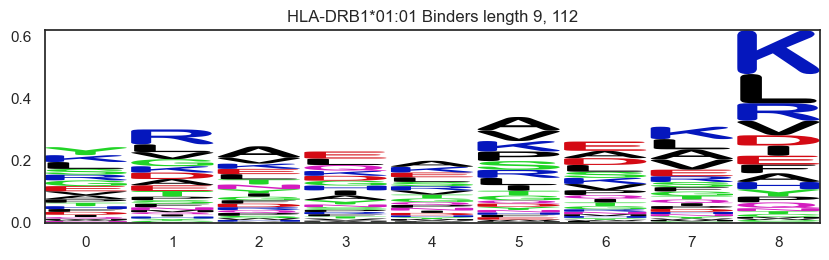

In [25]:

target_length = 9
peptides = per_allele_per_kfold_per_length_binders_train[target_allele][0][target_length]
make_logo_for_data(peptides, f"{ target_allele} Binders length {target_length}")

# Transform data

In [26]:
from data_reading_methods import merge_per_allele_sets_into_combination_sets

per_allele_per_kfold_per_length_binders_train_old = per_allele_per_kfold_per_length_binders_train
per_allele_per_kfold_per_length_binders_test_old = per_allele_per_kfold_per_length_binders_test


if check_peptides:
    transform_dicts=None

per_allele_per_kfold_per_length_binders_train, per_allele_per_kfold_per_length_binders_test = merge_per_allele_sets_into_combination_sets(
    per_allele_per_kfold_per_length_binders_train, per_allele_per_kfold_per_length_binders_test,
    combination_size=combination_size,
    selected_alelles=ALLELES,
    total_splits=TOTAL_SPLITS,
    list_of_transform_dicts=None
)
OLD_ALLELES = ALLELES
NEW_ALLELES = list(per_allele_per_kfold_per_length_binders_test.keys())
ALLELES = NEW_ALLELES

HLA-DRB1*01:01
Length 8: HLA-DRB1*01:01 - 39 
Length 9: HLA-DRB1*01:01 - 112 
Length 10: HLA-DRB1*01:01 - 123 
Length 11: HLA-DRB1*01:01 - 167 
Length 12: HLA-DRB1*01:01 - 357 
Length 13: HLA-DRB1*01:01 - 812 
Length 14: HLA-DRB1*01:01 - 1251 
Length 15: HLA-DRB1*01:01 - 5369 
Length 16: HLA-DRB1*01:01 - 1449 
Length 17: HLA-DRB1*01:01 - 991 
Length 18: HLA-DRB1*01:01 - 661 
Length 19: HLA-DRB1*01:01 - 312 
Length 20: HLA-DRB1*01:01 - 413 
Length 21: HLA-DRB1*01:01 - 161 
Length 22: HLA-DRB1*01:01 - 80 
Length 23: HLA-DRB1*01:01 - 60 
Length 24: HLA-DRB1*01:01 - 66 
Length 25: HLA-DRB1*01:01 - 46 
Length 26: HLA-DRB1*01:01 - 12 
Length 27: HLA-DRB1*01:01 - 11 
Length 28: HLA-DRB1*01:01 - 7 
Length 30: HLA-DRB1*01:01 - 6 


In [27]:
ALLELES

['HLA-DRB1*01:01']

## 2.2 Calculate counts of initial data (will be used to calculate weights further)

In [28]:
from data_reading_methods import extract_count_df, calculate_weights_based_on_length_counts

count_df_train = extract_count_df(per_allele_per_kfold_per_length_binders_train_old,
                                  selected_alleles=OLD_ALLELES,
                                  total_splits=TOTAL_SPLITS)
count_df_test = extract_count_df(per_allele_per_kfold_per_length_binders_test_old,
                                 selected_alleles=OLD_ALLELES,
                                 total_splits=TOTAL_SPLITS)


In [29]:
count_df_train.index.levels

FrozenList([['HLA-DRB1*01:01'], [0, 1, 2, 3, 4], [8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 30]])

## 2.3 Weights for data based on counts

In [30]:
sub_count_df_train = count_df_train.loc[(count_df_train.index.get_level_values('split') == 0) &
                                        (count_df_train.index.get_level_values('allele').isin(ALLELES)) &
                                        (count_df_train.index.get_level_values('length').isin(TARGET_LENGTHS))]

In [31]:
sub_count_df_train['cnt'].sum()

10890

In [32]:
per_allele_per_kfold_per_length_weights = calculate_weights_based_on_length_counts(count_df_train,
                                                                                   selected_alleles=ALLELES,
                                                                                   total_splits=TOTAL_SPLITS,
                                                                                   selected_lengths=TARGET_LENGTHS,
                                                                                   use_weights=USE_WEIGHTS)

Total data length for split 0 is 10890
Weights for lentgh 12 are {'HLA-DRB1*01:01': 1}
Weights for lentgh 13 are {'HLA-DRB1*01:01': 1}
Weights for lentgh 14 are {'HLA-DRB1*01:01': 1}
Weights for lentgh 15 are {'HLA-DRB1*01:01': 1}
Weights for lentgh 16 are {'HLA-DRB1*01:01': 1}
Weights for lentgh 17 are {'HLA-DRB1*01:01': 1}
Weights for lentgh 18 are {'HLA-DRB1*01:01': 1}
Devide by 1
Combination HLA-DRB1*01:01, split 0: {12: array([1.]), 13: array([1.]), 14: array([1.]), 15: array([1.]), 16: array([1.]), 17: array([1.]), 18: array([1.])}
Total data length for split 1 is 10890
Weights for lentgh 12 are {'HLA-DRB1*01:01': 1}
Weights for lentgh 13 are {'HLA-DRB1*01:01': 1}
Weights for lentgh 14 are {'HLA-DRB1*01:01': 1}
Weights for lentgh 15 are {'HLA-DRB1*01:01': 1}
Weights for lentgh 16 are {'HLA-DRB1*01:01': 1}
Weights for lentgh 17 are {'HLA-DRB1*01:01': 1}
Weights for lentgh 18 are {'HLA-DRB1*01:01': 1}
Devide by 1
Combination HLA-DRB1*01:01, split 1: {12: array([1.]), 13: array([1.]

## Transform to properties

# 2. Train HMMS
## 2.1 Code for HMM
### 2.1.1 Training code

In [33]:
from hmm_logic_methods import train_model, save_model, add_more_states_and_reset_transitions, init_grouped_structure_model_joiners_and_cycles_here



## 2.2 Train
### 2.2.1 Define treshold

In [34]:
stop_threshold = 0
cutoff = 0.00005
per_symbol_portion = -5
for target_length in TARGET_LENGTHS:
    target_length_for_training = target_length
    train_size = len(per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length])
    ## Stop threshold Hardcoded here
    stop_threshold +=  abs(cutoff * train_size * per_symbol_portion  * target_length_for_training)
stop_threshold = stop_threshold / len(TARGET_LENGTHS)

params['stop_threshold'] = stop_threshold

stop_threshold

5.886357142857143

In [35]:
sum([item for item in per_allele_per_kfold_per_length_weights[ALLELES[0]][0][target_length] for target_length in TARGET_LENGTHS])

4627.0

### 2.2.2 Prepare  initial grouped structure models

In [36]:
prepared_model = init_grouped_structure_model_joiners_and_cycles_here(
    states_per_group=int(params['states_per_group']),
    number_of_groups=params['groups'],
    CYCLE_PSEUDOCOUNT=params['cycle_pseudocount'],
    freeze_distr=params['freeze_distr'],
    initial_params=initial_params,
    start_cycle=params['start_cycle'],
    end_cycle=params['end_cycle'],
    self_cycles=params['self_cycle'],
    discrete_distribution=check_peptides,
    equal_probs_for_cycle=params['equal_probs_for_cycle'],
    tie_cycle_states=params['tie_cycle_states'],
    anchor_max_components=params['anchor_top_aas'],
    anchor_states=params['anchor_states'],
    model_complexity=params['model_complexity'],
    anchor_default_pseudocount= params['anchor_default_pseudocount'],
    tie_anchor_states=params['tie_anchor_states'],
                    intermediate_cycles=params['intermediate_cycles'],
                    equal_probs_for_intermediate_cycle=params['equal_probs_for_intermediate_cycle'],
                    tie_intermediate_cycles=params['tie_intermediate_cycles'],
                    freeze_int_cycle_distr=params['freeze_int_cycle_distr']
)

states will be groups:14 + joiners:4 + start/end cycles:4 + int_cycles:0


In [37]:
with open('model.png', 'w+') as f:
    prepared_model.plot(file=f, crop_zero=True, rotation=90, rotate=90)

In [38]:
from hmm_visualization_methods import *
plot_distributions_for_states(prepared_model,"test/", horizontal=False, discrete=check_peptides, initial_params=initial_params)

In [39]:

make_pyviz_graph(prepared_model, "test/", precision=3)

Converting graph for model (grouped_model) (Delete zero edges)


<class 'pyvis.network.Network'> |N|=24 |E|=62

In [40]:
prepared_model.states[11]

{
    "class" : "State",
    "distribution" : {
        "class" : "Distribution",
        "dtype" : "str",
        "name" : "DiscreteDistribution",
        "parameters" : [
            {
                "A" : 0.05563086956947361,
                "C" : 0.045239929329033764,
                "D" : 0.07485096665235566,
                "E" : 0.017467292823720823,
                "F" : 0.047318793985207934,
                "G" : 0.07734267954031611,
                "H" : 0.083006245349582,
                "I" : 0.005255513431128127,
                "K" : 0.05387346982352382,
                "L" : 0.086577604998634,
                "M" : 0.042629234704434214,
                "N" : 0.06882232139306316,
                "P" : 0.018747650859898116,
                "Q" : 0.011795385571942575,
                "R" : 0.06306984393321367,
                "S" : 0.000512680149703235,
                "T" : 0.07642070955972173,
                "V" : 0.06917974817240032,
                "W" : 0.05721036191

## Prepare models

In [41]:
per_allele_per_run_per_split_prepared_models = dict()
for allele_name in ALLELES:
    target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_').replace('/', '_')
    per_allele_per_run_per_split_prepared_models[allele_name] = dict()
    for run_num in range(NUM_RUNS):
        per_allele_per_run_per_split_prepared_models[allele_name][run_num] = dict()
        for split_num in range(TOTAL_SPLITS):
            # prepared_model  = init_grouped_structure_model(states_per_group=int(params['st']/params['groups']), number_of_groups=params['groups'])
            prepared_model = init_grouped_structure_model_joiners_and_cycles_here(
                states_per_group=int(params['states_per_group']),
                number_of_groups=params['groups'],
                CYCLE_PSEUDOCOUNT=params['cycle_pseudocount'],
                freeze_distr=params['freeze_distr'],
                initial_params=initial_params,
                start_cycle=params['start_cycle'],
                end_cycle=params['end_cycle'],
                self_cycles=params['self_cycle'],
                discrete_distribution=check_peptides,
                equal_probs_for_cycle=params['equal_probs_for_cycle'],
                tie_cycle_states=params['tie_cycle_states'],
                 model_complexity=params['model_complexity'],
                     anchor_default_pseudocount= params['anchor_default_pseudocount'] ,
             anchor_max_components=params['anchor_top_aas'],
                anchor_states=params['anchor_states'],
                   tie_anchor_states=params['tie_anchor_states'],
                    intermediate_cycles=params['intermediate_cycles'],
                    equal_probs_for_intermediate_cycle=params['equal_probs_for_intermediate_cycle'],
                    tie_intermediate_cycles=params['tie_intermediate_cycles'],
                    freeze_int_cycle_distr=params['freeze_int_cycle_distr']

            )



            prepared_model.name = f'{run_num}_run-{lengths_string}-{params_string}_model-{target_allele_name}-{split_num}'
            per_allele_per_run_per_split_prepared_models[allele_name][run_num][split_num] = prepared_model

states will be groups:14 + joiners:4 + start/end cycles:4 + int_cycles:0
states will be groups:14 + joiners:4 + start/end cycles:4 + int_cycles:0
states will be groups:14 + joiners:4 + start/end cycles:4 + int_cycles:0
states will be groups:14 + joiners:4 + start/end cycles:4 + int_cycles:0
states will be groups:14 + joiners:4 + start/end cycles:4 + int_cycles:0
states will be groups:14 + joiners:4 + start/end cycles:4 + int_cycles:0
states will be groups:14 + joiners:4 + start/end cycles:4 + int_cycles:0
states will be groups:14 + joiners:4 + start/end cycles:4 + int_cycles:0
states will be groups:14 + joiners:4 + start/end cycles:4 + int_cycles:0
states will be groups:14 + joiners:4 + start/end cycles:4 + int_cycles:0
states will be groups:14 + joiners:4 + start/end cycles:4 + int_cycles:0
states will be groups:14 + joiners:4 + start/end cycles:4 + int_cycles:0
states will be groups:14 + joiners:4 + start/end cycles:4 + int_cycles:0
states will be groups:14 + joiners:4 + start/end cy

In [42]:
# cycle_state = prepared_model.states[27]
# start = prepared_model.states[29]
# prepared_model.graph.edges()[cycle_state, cycle_state]

## Do training

In [43]:
%%time
TOTAL_SPLITS = 1
per_name_models = dict()
per_allele_per_run_per_split_new_histories = dict()
for allele_name in ALLELES:
    per_allele_per_run_per_split_new_histories[allele_name] = dict()
    for run_num in range(NUM_RUNS):
        print(f"run {run_num}")
        per_kfold_per_length_data = per_allele_per_kfold_per_length_binders_train[allele_name]
        per_kfold_per_length_weights = per_allele_per_kfold_per_length_weights[allele_name]
        


        models, histories = train_model(allele_name=allele_name,
                                        per_kfold_per_length_data=per_kfold_per_length_data,
                                        per_kfold_per_length_weights_for_data=per_kfold_per_length_weights,
                                        target_lengths=TARGET_LENGTHS,
                                        multiple_check_input=params['multiple_check_input'],
                                        algorithm=params['alg'],
                                        verbose=params['verbose'],
                                        per_kfold_per_length_test_data=per_allele_per_kfold_per_length_binders_test[allele_name],
                                        stop_threshold=params['stop_threshold'],
                                        min_iterations= params['min_iters'],
                                        max_iterations=params['max_iters'],
                                        prepared_models=per_allele_per_run_per_split_prepared_models[allele_name][run_num],
                                        emission_pseudocount=params['emission_pseudocount'],
                                        transition_pseudocount=params['transition_pseudocount'],
                                        edge_inertia=params['edge_inertia'],
                                        distribution_inertia=params['distribution_inertia'],
                                        lr_decay=params['lr_decay'],
                                        use_pseudocount=params['use_pseudocount'],
                                       n_jobs=3)

        per_allele_per_run_per_split_prepared_models[allele_name][run_num] = models
        per_allele_per_run_per_split_new_histories[allele_name][run_num] = histories
        # per_allele_per_run_per_split_models[allele_name][run_num] = models
        for split_num, model in models.items():
            per_name_models[model.name] = model
        # save models
        for split_num, model in models.items():
            history = histories[split_num]
            save_model(TARGET_PATH_TO_RESULTS, model,history)



run 0
split 0
train size 10890
Shuffling for fairness 
Simple training: Train Length 10890, init_batch_size None
Example of data ['Y', 'D', 'L', 'M', 'D', 'N', 'K', 'D', 'K', 'G', 'S', 'S']
Use pseudocount is True
[1] Improvement: 19901.57955789141	Time (s): 2.446
[2] Improvement: 5339.865643354249	Time (s): 2.58
[3] Improvement: 1630.9750474523753	Time (s): 2.339
[4] Improvement: 734.3744886799832	Time (s): 2.319
[5] Improvement: 563.3579773527454	Time (s): 2.316
[6] Improvement: 619.0439710845822	Time (s): 2.434
[7] Improvement: 651.3346280157566	Time (s): 2.488
[8] Improvement: 719.7446406699019	Time (s): 2.766
[9] Improvement: 824.526580445643	Time (s): 2.925
[10] Improvement: 885.051373008173	Time (s): 2.913
[11] Improvement: 919.2852653738228	Time (s): 2.993
[12] Improvement: 909.5634483349859	Time (s): 2.662
[13] Improvement: 915.2906759124598	Time (s): 2.471
[14] Improvement: 813.2086604940123	Time (s): 2.618
[15] Improvement: 732.908913844265	Time (s): 2.934
[16] Improvement: 

In [44]:

# Sort by score
per_name_new_models = dict()
per_name_histories = dict()
for split_num in range(TOTAL_SPLITS):
    for allele_name in ALLELES:
        df = pd.DataFrame({"model": np.arange(NUM_RUNS), 
                          "log_probability": [per_allele_per_run_per_split_new_histories[allele_name][i][split_num].log_probabilities[-1]
                                             for i in range(NUM_RUNS)],
                          "test_log_probability":  [per_allele_per_run_per_split_new_histories[allele_name][i][split_num].test_log_probability[-1]
                                             for i in range(NUM_RUNS)]})
        df = df.sort_values(by='log_probability', ascending = False).reset_index(drop=True)
        for new_index, model_run_num in zip(np.arange(len(df)), df.model):
            original_model =  per_allele_per_run_per_split_prepared_models[allele_name][model_run_num][split_num]
            original_history = per_allele_per_run_per_split_new_histories[allele_name][model_run_num][split_num]
            original_model_name = original_model.name
            rest_part = original_model_name.split("_", 1)[1]
            new_name = f"{new_index}_{rest_part}"
            original_model.name = new_name
            per_name_new_models[new_name] = original_model
            per_name_histories[new_name] = original_history
per_name_models = per_name_new_models
        
        

In [45]:
for name, model in per_name_models.items():
    history = per_name_histories[name]
    save_model(TARGET_PATH_TO_RESULTS, model,history)
    

In [46]:
per_name_models = per_name_new_models

In [47]:
from hmm_visualization_methods import *

<AxesSubplot: >

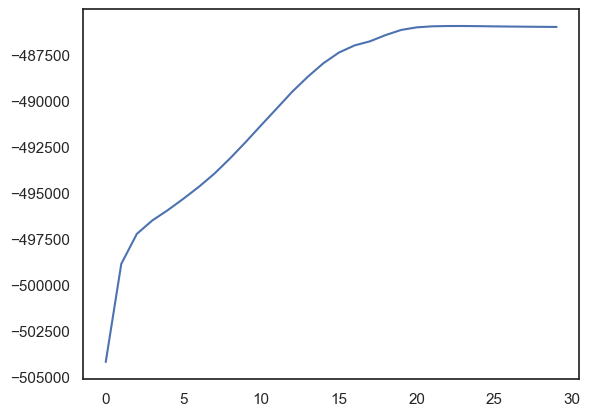

In [48]:
sns.lineplot(
    per_name_histories[
        list(per_name_histories.keys())[0]
    ].log_probabilities)

In [49]:
%%time

for i, model in enumerate(per_name_models.values()):
    print(i)
    # with open(f"{TARGET_PATH_TO_RESULTS}{model.name}/state_graph.png", 'w+') as f:
    #     model.plot(file=f, crop_zero=False)
    with open(f"{TARGET_PATH_TO_RESULTS}{model.name}/state_graph_cropped.png", 'w+') as f:
        model.plot(file=f, crop_zero=True)

0
1
2
CPU times: total: 31.2 ms
Wall time: 3.94 s


In [50]:
%%time

for i, model in enumerate(per_name_models.values()):
    plot_distributions_for_states(model,TARGET_PATH_TO_RESULTS, horizontal=False, discrete=check_peptides, initial_params=initial_params)
    print(i)

0
1
2
CPU times: total: 52.5 s
Wall time: 1min 11s


In [51]:
from hmm_visualization_methods import *


per_name_pyviz = dict()
for name, model in per_name_models.items():
    per_name_pyviz[name] = make_pyviz_graph(model, TARGET_PATH_TO_RESULTS, precision=3)

Converting graph for model (0_run-12-13-14-15-16-17-18-14-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0) (Delete zero edges)
Converting graph for model (1_run-12-13-14-15-16-17-18-14-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0) (Delete zero edges)
Converting graph for model (2_run-12-13-14-15-16-17-18-14-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0) (Delete zero edges)


## See how viterbi steps look like

In [148]:
peptide = per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][16][0]

In [72]:
per_length_data =  per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0]
binders_array = np.array([per_length_data[target_length][i] for target_length in [16]
                          for i in range(len(per_length_data[target_length]))], dtype=object)

In [28]:
binders_array = binders_array[0:2]

In [29]:
binders_array = np.array(['AAAAAAAAAAAAAAAA', 'EEEEEEEEEEEEEEEE'])

In [30]:
prob, path, e, v, tracex, tracey = prepared_model.viterbi_with_track(peptide)

26


In [31]:
prob

-58.855955734206276

In [48]:
[item[1].name for item in path]

['grouped_model-start',
 's022',
 's022',
 's022',
 's015',
 's001',
 's003',
 's005',
 's004',
 's007',
 's008',
 's011',
 's013',
 's017',
 's024',
 's024',
 's024',
 'grouped_model-end']

In [33]:
e_df = pd.DataFrame(e)
v_df = pd.DataFrame(v)
tracex_df = pd.DataFrame(tracex)
tracey_df= pd.DataFrame(tracey)


In [34]:
peptide

'AEEYEFLTPVEEAPKG'

In [35]:
np.log(prepared_model.states[0].distribution.parameters[0][peptide[5]])

-3.7734215388890737

In [36]:
prepared_model.states[0].distribution.parameters[0]

{'A': 0.07571864783809087,
 'C': 0.06254418503576804,
 'D': 0.08331451079503237,
 'E': 0.030616335700290633,
 'F': 0.02297332453687886,
 'G': 0.043881124915521985,
 'H': 0.03380302320170897,
 'I': 0.061296119576208084,
 'K': 0.03253901063566612,
 'L': 0.04666437904809656,
 'M': 0.05328550684307483,
 'N': 0.02592917436634595,
 'P': 0.08638586105530684,
 'Q': 0.08543734148107672,
 'R': 0.05072254912358455,
 'S': 0.08337051741610775,
 'T': 0.0517078702789842,
 'V': 0.01883451763726147,
 'W': 0.04839971216457733,
 'Y': 0.0025762883504177937}

In [ ]:
np.log(prepared_model.dense_transition_matrix()[29, 25]) + e_df.loc[1,25]

In [39]:
e_df

,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,-2.580731,-2.482486,-2.354870,-2.548942,-3.323714,-3.457751,-3.227558,-2.910144,-2.705478,-4.243676,...,-2.901509,-2.654258,-2.560407,-2.579879,-3.983075,-2.588316,-2.588063,-2.517260,-4.510434,-2.363846
1,-3.486222,-2.454806,-2.239828,-2.552755,-4.686663,-4.411393,-3.750299,-3.600780,-2.791509,-4.113877,...,-2.558367,-2.744073,-3.076836,-2.656939,-2.376146,-3.707400,-2.974316,-4.887709,-2.420711,-4.448130
2,-3.486222,-2.454806,-2.239828,-2.552755,-4.686663,-4.411393,-3.750299,-3.600780,-2.791509,-4.113877,...,-2.558367,-2.744073,-3.076836,-2.656939,-2.376146,-3.707400,-2.974316,-4.887709,-2.420711,-4.448130
3,-5.961406,-4.204573,-2.471057,-6.667260,-3.015362,-2.518326,-2.560900,-2.298881,-3.900270,-3.758152,...,-2.669119,-2.766200,-7.570643,-3.179690,-2.469712,-2.490153,-3.582216,-2.394875,-2.265235,-2.804881
4,-3.486222,-2.454806,-2.239828,-2.552755,-4.686663,-4.411393,-3.750299,-3.600780,-2.791509,-4.113877,...,-2.558367,-2.744073,-3.076836,-2.656939,-2.376146,-3.707400,-2.974316,-4.887709,-2.420711,-4.448130
5,-3.773422,-3.149086,-8.678973,-2.528535,-4.463481,-2.607273,-6.633460,-5.917249,-2.338437,-2.780633,...,-3.066331,-2.586509,-4.784634,-4.835911,-2.359273,-4.051830,-2.595513,-2.985037,-3.094734,-4.015556
6,-3.064774,-3.041179,-3.682080,-2.797805,-2.668819,-2.511064,-2.509698,-2.381557,-5.754702,-2.420068,...,-4.803543,-5.509458,-2.554017,-2.519608,-2.942995,-2.495937,-2.369921,-2.896592,-3.253649,-2.350750
7,-2.962145,-3.337107,-2.657399,-2.344316,-2.787910,-4.304289,-3.298894,-3.282717,-2.834962,-2.273780,...,-2.448051,-4.858807,-2.313991,-3.104743,-3.188868,-3.288496,-2.331519,-2.736251,-2.789447,-2.474218
8,-2.448931,-3.030831,-5.285374,-4.833995,-2.546988,-2.823981,-2.685203,-2.346380,-4.444749,-2.656821,...,-2.454234,-2.767930,-2.634234,-9.643275,-2.994439,-3.068497,-3.750081,-7.138765,-2.827976,-2.859215
9,-3.972064,-6.112308,-2.440340,-3.126467,-2.664258,-2.735279,-2.949482,-3.670208,-2.587258,-3.426879,...,-2.496241,-2.643979,-3.086375,-4.413018,-3.211736,-4.204467,-3.198508,-2.845319,-6.577611,-3.430613


<AxesSubplot: >

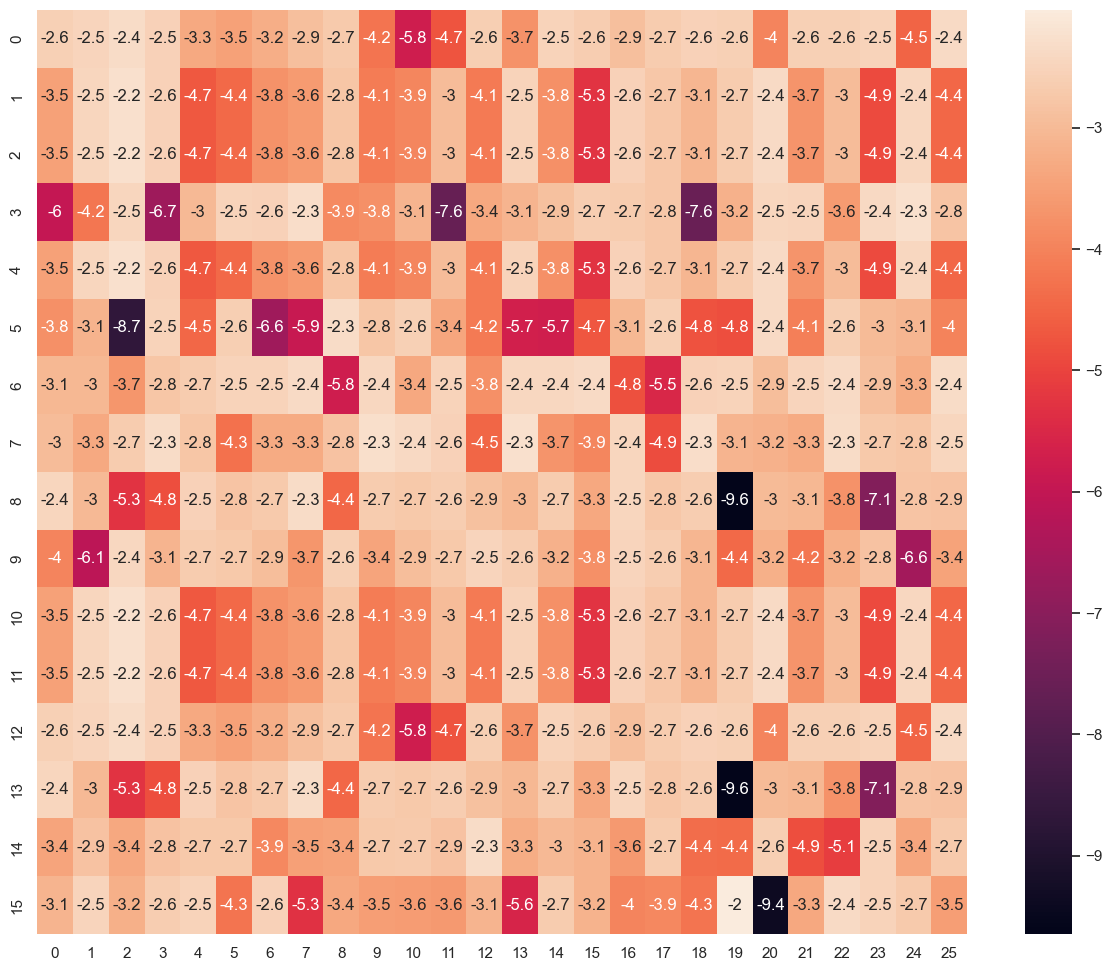

In [40]:
plt.figure(figsize=(15,12))
sns.heatmap(e_df, annot=True)

In [41]:
np.log(0.41)

-0.8915981192837836

In [40]:
prepared_model.start_index

29

In [58]:
v_df

,0,1,2,3,4,5,6,7,8,9,...,21,22,23,24,25,26,27,28,29,30
0,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,...,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,0.0,-inf
1,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,...,-6.101276,-7.356512,-inf,-inf,-3.240078,-3.638830,-inf,-inf,-inf,-inf
2,-10.161856,-9.889668,-9.636241,-inf,-inf,-inf,-inf,-inf,-inf,-inf,...,-8.653246,-6.610147,-inf,-inf,-6.373518,-6.926865,-inf,-inf,-inf,-inf
3,-10.670728,-10.398539,-10.145112,-16.340274,-13.707774,-16.126646,-inf,-inf,-inf,-inf,...,-11.786686,-9.898181,-inf,-inf,-9.506957,-10.214899,-inf,-inf,-inf,-inf
4,-13.635782,-15.357454,-14.343199,-14.103337,-15.018467,-14.479895,-18.748601,-20.146401,-18.255889,-inf,...,-14.111600,-14.036095,-inf,-inf,-18.103754,-14.321330,-inf,-inf,-inf,-inf
5,-18.096676,-17.824488,-17.571061,-20.339815,-17.707315,-20.126187,-20.425451,-18.988105,-19.376932,-22.469402,...,-23.516922,-17.292647,-inf,-inf,-21.237193,-17.609365,-inf,-inf,-inf,-inf
6,-21.356499,-21.249655,-20.979244,-21.655320,-21.703593,-21.522794,-23.951168,-26.010941,-21.958781,-23.067706,...,-24.278736,-21.306241,-inf,-inf,-25.767472,-21.337198,-inf,-inf,-inf,-inf
7,-24.839602,-25.009903,-25.494939,-25.700614,-30.223841,-26.679253,-26.537278,-25.555923,-26.994174,-26.062913,...,-29.210235,-24.439600,-inf,-inf,-28.989549,-24.788406,-inf,-inf,-inf,-inf
8,-27.952776,-31.947481,-29.148721,-29.291166,-29.819414,-28.836786,-30.258266,-30.344030,-29.706959,-29.798626,...,-32.984570,-27.902481,-inf,-inf,-32.994537,-28.538222,-inf,-inf,-inf,-inf
9,-31.616303,-31.967104,-31.607997,-33.154984,-31.892802,-31.688353,-32.810522,-35.046768,-33.923038,-35.359177,...,-36.131114,-32.534341,-40.631014,-41.442518,-37.465072,-32.012744,-inf,-inf,-inf,-42.422774


<AxesSubplot: >

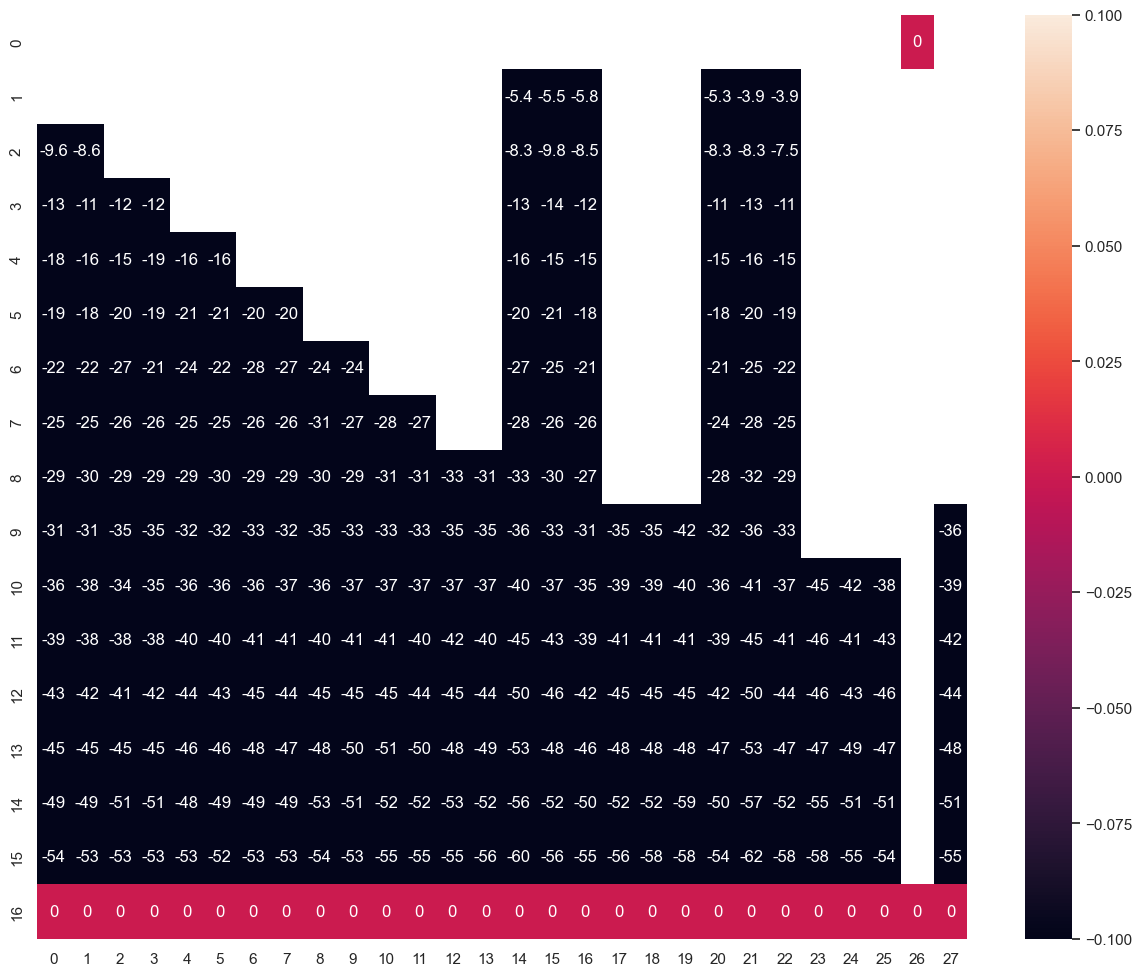

In [41]:
plt.figure(figsize=(15,12))
sns.heatmap(v_df, annot=True)

In [42]:
v_df1 = v_df.divide(v_df.index, axis="rows")

<AxesSubplot: >

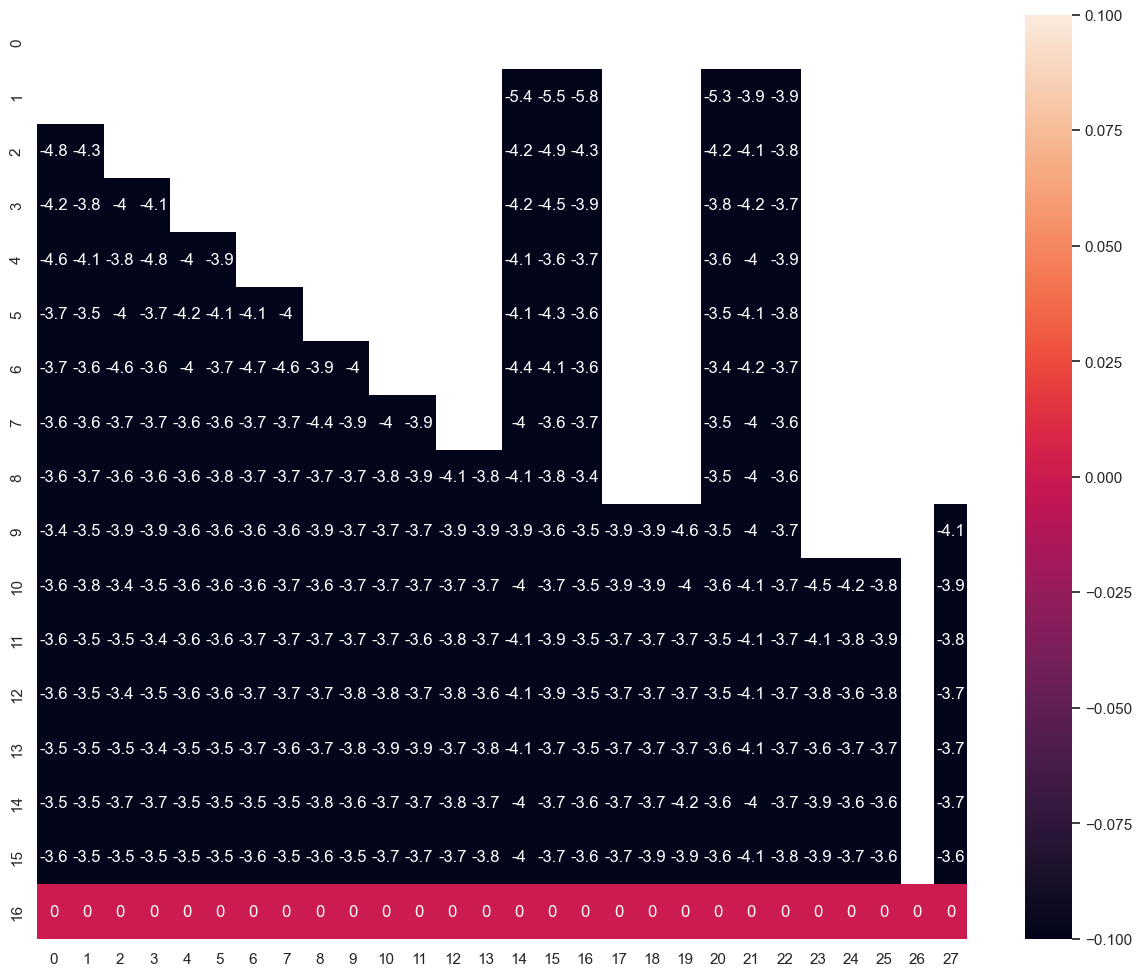

In [43]:
plt.figure(figsize=(15,12))
sns.heatmap(v_df1, annot=True)

<AxesSubplot: >

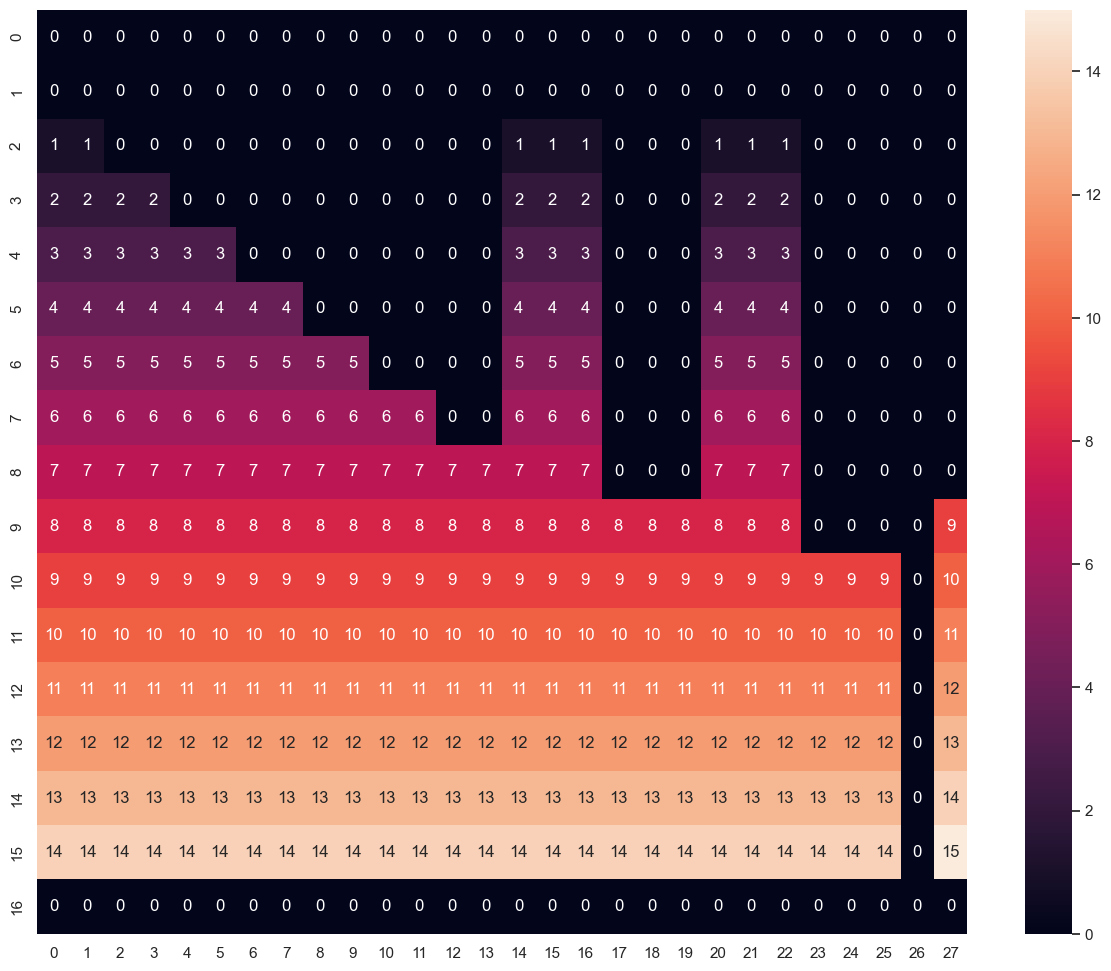

In [46]:
plt.figure(figsize=(15,12))
sns.heatmap(tracex_df, annot=True)

<AxesSubplot: >

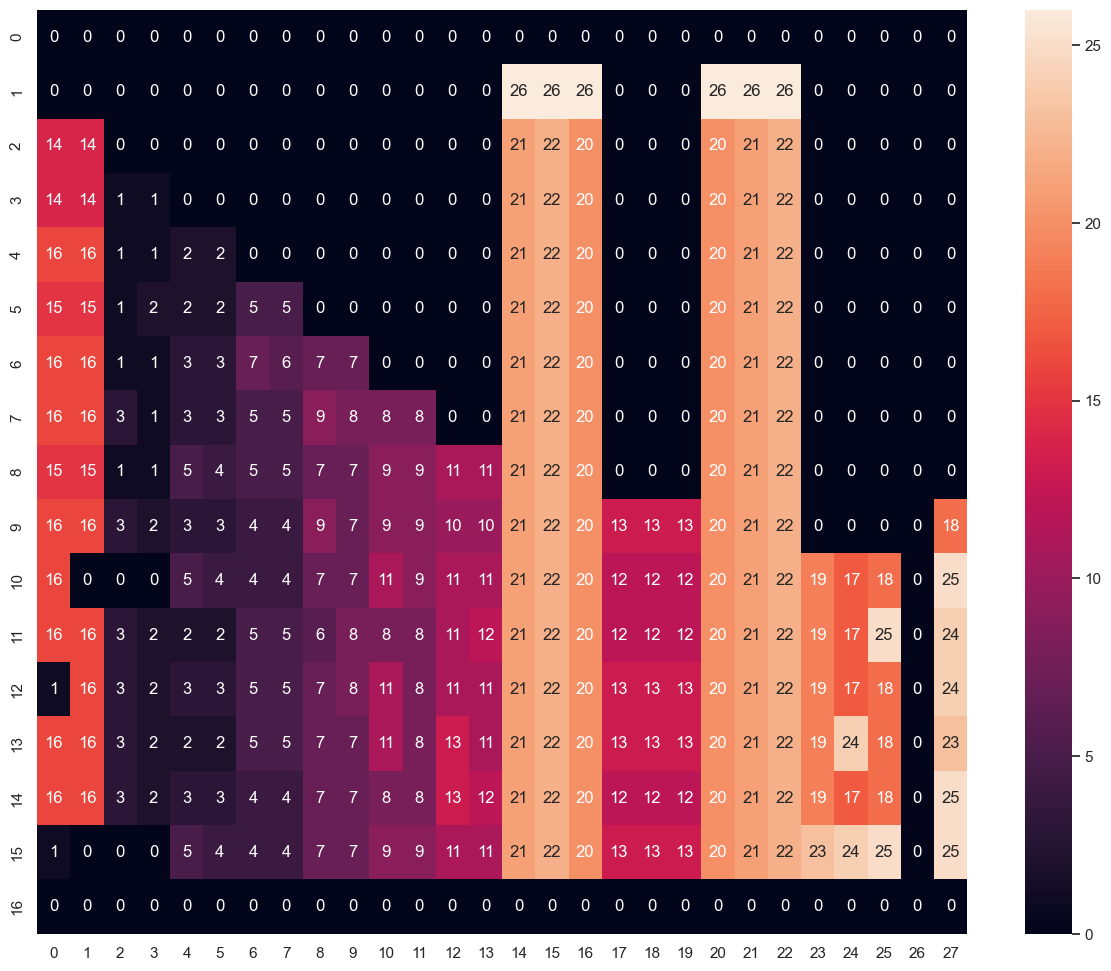

In [47]:
plt.figure(figsize=(15,12))
sns.heatmap(tracey_df, annot=True)

In [38]:
pd.DataFrame(v)

,0,1,2,3,4,5,6,7,8,9,...,21,22,23,24,25,26,27,28,29,30
0,-inf,-inf,-inf,-inf,-9.897697,-inf,-14.766246,-inf,-16.200919,-inf,...,-39.604064,-41.711614,-43.918442,-47.069740,-46.702237,-49.703034,-inf,-54.077506,-54.158469,-58.417470
1,-inf,-inf,-inf,-inf,-inf,-inf,-13.353832,-inf,-15.546060,-20.289434,...,-45.593630,-43.111042,-44.673637,-47.088262,-inf,-50.387610,-50.969306,-54.185503,-58.623886,-58.556086
2,-inf,-inf,-inf,-inf,-inf,-inf,-12.744076,-13.676643,-17.770896,-16.632373,...,-42.143304,-43.129564,-inf,-45.743001,-47.395384,-49.956424,-54.030597,-54.636203,-55.556903,-58.255087
3,-inf,-inf,-inf,-inf,-inf,-7.006193,-inf,-9.924912,-17.465036,-inf,...,-inf,-41.784303,-44.611589,-46.290730,-49.811253,-50.361343,-54.075790,-55.720645,-56.460997,-58.421637
4,-inf,-inf,-inf,-6.005827,-inf,-6.741011,-inf,-inf,-17.657511,-inf,...,-41.938631,-43.553044,-46.099337,-47.028608,-51.254448,-50.509471,-52.941969,-54.202038,-57.923339,-58.378270
5,-inf,-inf,-inf,-5.200014,-inf,-inf,-inf,-inf,-inf,-22.371744,...,-41.447697,-44.290923,-45.847664,-45.748991,-51.537231,-50.796434,-53.230822,-54.202323,-57.320290,-60.153764
6,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-16.927373,-inf,-14.048081,...,-41.908967,-43.011305,-46.656206,-49.086513,-49.517435,-51.266869,-53.535436,-54.333524,-57.057929,-71.395451
7,-inf,-inf,-inf,-inf,-inf,-10.256922,-inf,-9.740006,-inf,-inf,...,-42.465835,-44.928082,-46.899330,-48.268561,-49.242663,-50.168971,-53.318243,-67.789946,-57.339391,-57.512264
8,-inf,-inf,-inf,-3.586472,-inf,-6.556105,-inf,-inf,-inf,-inf,...,-42.860322,-44.110129,-45.486916,-48.207960,-50.399682,-64.643674,-53.735852,-52.094815,-57.252159,-58.357634
9,-inf,-inf,-inf,-3.372205,-inf,-inf,-inf,-inf,-inf,-inf,...,-41.447909,-44.619469,-45.312214,-57.178877,-50.024967,-49.380121,-57.106496,-54.939432,-57.456608,-58.124237


In [39]:
pd.DataFrame(tracex)

,0,1,2,3,4,5,6,7,8,9,...,21,22,23,24,25,26,27,28,29,30
0,0.0,0.0,0.0,0.0,1.0,0.0,2.0,0.0,3.0,0.0,...,9.0,10.0,10.0,11.0,11.0,12.0,0.0,13.0,14.0,14.0
1,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,3.0,3.0,...,9.0,10.0,10.0,11.0,0.0,12.0,13.0,13.0,14.0,14.0
2,0.0,0.0,0.0,0.0,0.0,0.0,2.0,2.0,3.0,3.0,...,9.0,10.0,0.0,11.0,12.0,12.0,13.0,13.0,14.0,14.0
3,0.0,0.0,0.0,0.0,0.0,1.0,0.0,2.0,3.0,0.0,...,0.0,10.0,11.0,11.0,12.0,12.0,13.0,13.0,14.0,14.0
4,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,3.0,0.0,...,10.0,10.0,11.0,11.0,12.0,12.0,13.0,13.0,14.0,14.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,...,10.0,10.0,11.0,11.0,12.0,12.0,13.0,13.0,14.0,14.0
6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,3.0,...,10.0,10.0,11.0,11.0,12.0,12.0,13.0,13.0,14.0,14.0
7,0.0,0.0,0.0,0.0,0.0,1.0,0.0,2.0,0.0,0.0,...,10.0,10.0,11.0,11.0,12.0,12.0,13.0,13.0,14.0,14.0
8,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,10.0,10.0,11.0,11.0,12.0,12.0,13.0,13.0,14.0,14.0
9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,10.0,10.0,11.0,11.0,12.0,12.0,13.0,13.0,14.0,14.0


In [40]:
pd.DataFrame(tracey)

,0,1,2,3,4,5,6,7,8,9,...,21,22,23,24,25,26,27,28,29,30
0,0.0,0.0,0.0,0.0,22.0,0.0,0.0,0.0,0.0,0.0,...,26.0,10.0,24.0,11.0,23.0,11.0,0.0,9.0,28.0,14.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,25.0,...,24.0,10.0,23.0,11.0,0.0,11.0,28.0,13.0,22.0,14.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,25.0,5.0,26.0,...,23.0,10.0,0.0,11.0,28.0,14.0,22.0,13.0,22.0,14.0
3,0.0,0.0,0.0,0.0,0.0,25.0,0.0,26.0,5.0,0.0,...,0.0,10.0,27.0,14.0,22.0,14.0,22.0,13.0,22.0,19.0
4,0.0,0.0,0.0,29.0,0.0,26.0,0.0,0.0,5.0,0.0,...,24.0,13.0,1.0,14.0,22.0,14.0,22.0,20.0,2.0,18.0
5,0.0,0.0,0.0,29.0,0.0,0.0,0.0,0.0,0.0,25.0,...,1.0,13.0,0.0,14.0,22.0,17.0,4.0,20.0,2.0,18.0
6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,25.0,0.0,26.0,...,0.0,13.0,0.0,17.0,5.0,17.0,3.0,15.0,2.0,25.0
7,0.0,0.0,0.0,0.0,0.0,25.0,0.0,26.0,0.0,0.0,...,1.0,20.0,5.0,17.0,5.0,17.0,4.0,25.0,3.0,26.0
8,0.0,0.0,0.0,29.0,0.0,26.0,0.0,0.0,0.0,0.0,...,5.0,20.0,5.0,17.0,4.0,25.0,4.0,26.0,3.0,18.0
9,0.0,0.0,0.0,29.0,0.0,0.0,0.0,0.0,0.0,0.0,...,5.0,18.0,0.0,25.0,5.0,26.0,4.0,20.0,3.0,18.0


In [ ]:
# allele_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length] for target_length in TARGET_LENGTHS])
# ten_mer = allele_peptides[12]
# print(ten_mer, len(ten_mer))
#prob, path = model.viterbi(ten_mer)
#print([item[0] for item in path])
# sixteen_mer = peptide_properties[8900]
# print(sixteen_mer, len(sixteen_mer))

In [28]:
#pd.DataFrame(model.forward(sixteen_mer))

In [29]:
#pd.DataFrame(model.forward_backward(sixteen_mer)[1])

In [30]:
#pd.DataFrame(model.forward_backward(ten_mer)[1])

In [31]:
#ten_mer

In [32]:
#state_sums = [sum(state.distribution.parameters[0].values()) for state in model.states[:-2]]
# assert np.isclose(sum(state_sums), len(state_sums))

## Training steps

In [ ]:

params['st'] = 21
params['multiple_check_input'] = False
params['alg'] = algorithm
params['min_iters'] = 30
params['max_iters'] = 65
params['stop_threshold'] = stop_threshold
params['emission_pseudocount'] = 1
params['transition_pseudocount'] = 1
params['verbose'] = True
params['lr_decay'] = 0.9
params['edge_inertia'] = 0.4
params['distribution_inertia'] = 0.4
params['groups'] = 7
params['states_per_group'] = 3
params['model_complexity'] = 3
params['use_pseudocount'] = True

# Class 1 params
params['self_cycle'] = False
params['start_cycle'] = True
params['end_cycle'] = True
params['equal_probs_for_cycle'] = False

params['freeze_distr'] = False # wether to freeze start and end cycle distributions
params['tie_cycle_states'] = False
params['cycle_pseudocount'] = 300

In [234]:
allele_name = ALLELES[0]
per_kfold_per_length_train_data = per_allele_per_kfold_per_length_binders_train[allele_name]
per_kfold_per_length_test_data = per_allele_per_kfold_per_length_binders_test[allele_name]
per_kfold_per_length_weights_for_data = per_allele_per_kfold_per_length_weights[allele_name]
split_num = 0
target_lengths = TARGET_LENGTHS
per_length_current_weights = per_kfold_per_length_weights_for_data[split_num]
per_length_data = per_kfold_per_length_train_data[split_num]

per_length_test_data = per_kfold_per_length_test_data[split_num]
per_length_counts = {target_length: len(per_length_data[target_length]) for target_length in target_lengths}

# list_of_arrays = [per_length_data[target_length] for target_length in target_lengths]
# list_of_arrays_for_weights = [np.array(per_length_current_weights[target_length]) for target_length in
#                               target_lengths]
# list_of_test_arrays = [per_length_test_data[target_length] for target_length in target_lengths]
# binders_array = np.concatenate(list_of_arrays)
# weights_array = np.concatenate(list_of_arrays_for_weights)
#
# binders_test_array = np.concatenate(list_of_test_arrays)

binders_array = np.array([per_length_data[target_length][i] for target_length in target_lengths
                          for i in range(len(per_length_data[target_length]))], dtype=object)
weights_array = np.array([per_length_current_weights[target_length][i] for target_length in target_lengths
                          for i in range(len(per_length_current_weights[target_length]))], dtype=object)

binders_test_array = np.array([per_length_test_data[target_length][i] for target_length in target_lengths
                               for i in range(len(per_length_test_data[target_length]))], dtype=object)
print("split {}".format(split_num))
print("train size {}".format(len(binders_array)))
# total_length = len(binders_array)
#  weights = [1 - per_length_counts[len(peptide)]/total_length for peptide in binders_array]
# print("weights for lengths {}".format({key: 1 - value/total_length for key, value in per_length_counts.items()}))
print("Shuffling for fairness ")

rng = np.random.default_rng()
# shuffle train data and weights in unison
new_indexes = rng.permutation(len(binders_array))
binders_array = binders_array[new_indexes]
weights_array = weights_array[new_indexes]

# just shuffle test data
rng.shuffle(binders_test_array)
sample_X = np.array([[char for char in item] for item in binders_array], dtype=object)
sample_X_test = np.array([[char for char in item] for item in binders_test_array], dtype=object)

split 0
train size 5640
Shuffling for fairness 


In [235]:

sequence_generator = sample_X
sequence_test_generator = SequenceGenerator(sample_X_test)
data_generator = sequence_generator


In [236]:
data_generator = SequenceGenerator(sample_X, weights_array)

In [237]:
batches = [batch for batch in data_generator.batches()]

In [238]:
len(batches)

5640

In [ ]:
from hmm_visualization_methods import *

model_to_train = init_grouped_structure_model_joiners_and_cycles_here(
    states_per_group=int(params['states_per_group']),
    number_of_groups=params['groups'],
    CYCLE_PSEUDOCOUNT=params['cycle_pseudocount'],
    freeze_distr=params['freeze_distr'],
    initial_params=initial_params,
    start_cycle=params['start_cycle'],
    end_cycle=params['end_cycle'],
    self_cycles=params['self_cycle'],
    discrete_distribution=check_peptides,
    equal_probs_for_cycle=params['equal_probs_for_cycle'],
    tie_cycle_states=params['tie_cycle_states']
)
with open('model.png', 'w+') as f:
    model_to_train.plot(file=f, crop_zero=True, rotation=90, rotate=90)
    
    
def step(iteration):
    print(iteration)
    list_of_summaries = list()
    result = 0
    batch_size = len(binders_array)
    for set_num in range(1):
        cur_batch = batches[set_num*batch_size:(set_num+1)*batch_size]
        epoch_probs = list()
        for i, batch in enumerate(cur_batch):
            seq, weights = batch

            result += model_to_train.summarize(seq, weights, algorithm='viterbi')

        total_summaries = [state.distribution.summaries.copy() for state in model_to_train.states if state.distribution is not None]
        result_summaries[f"{iteration}_{set_num}"] = total_summaries


            # print(list_of_summaries[-1])
        step_size = None
        pseudocount = None
        transition_pseudocount = params['transition_pseudocount']
        emission_pseudocount = params['emission_pseudocount']
        use_pseudocount = params['use_pseudocount']
        edge_inertia = params['edge_inertia']
        distribution_inertia = params['distribution_inertia']

    #         new_edge_inertia = None if edge_inertia is None else 1 - ((1 - edge_inertia) * (2 + iteration) ** -params['lr_decay'])
    #         new_dist_inertia = None if edge_inertia is None else 1 - ((1 - distribution_inertia) * (2 + iteration) ** -params['lr_decay'])





        #  inertia=None, pseudocount=None,
        # transition_pseudocount=0.0, emission_pseudocount=0.0,
        # use_pseudocount=False, edge_inertia=0.0, distribution_inertia=0.0)


        model_to_train.from_summaries(inertia=step_size, 
                             pseudocount=pseudocount, 
                             transition_pseudocount=transition_pseudocount,
                             emission_pseudocount= emission_pseudocount,
                             use_pseudocount= use_pseudocount,
                             edge_inertia = edge_inertia, 
                             distribution_inertia=distribution_inertia)
        model_to_train.clear_summaries()
        model_to_train.update_transitions()
    probs.append(result)
    
    
    

result_summaries = dict()
iterations = 50
probs = list()
for iteration in range(iterations):
    step(iteration)
    
   



    # plot_distributions_for_states(prepared_model,f"test{it}/", horizontal=False, discrete=check_peptides, initial_params=initial_params)
    # make_pyviz_graph(prepared_model, f"test{it}/", precision=3)

In [ ]:
iter_num = 49
batch_num = 0

l = [item[0] for item in result_summaries[f"{iter_num}_{batch_num}"]]
df  = pd.DataFrame.from_dict(l, orient='columns')
df['Total']= df.sum(axis=1)
df

In [241]:
peptide = "".join(batches[2700][0][0])

In [ ]:
[item[1].name for item in model_to_train.viterbi(peptide)[1]]

In [ ]:
pd.DataFrame(model_to_train.backward(peptide))

In [ ]:
pd.DataFrame(model_to_train.forward(peptide))

In [ ]:
import seaborn as sns
sns.heatmap(df[df.columns[:-1]])

In [38]:
plot_distributions_for_states(model_to_train,f"test{iteration}/", horizontal=False, discrete=check_peptides, initial_params=initial_params)
make_pyviz_graph(model_to_train, f"test{iteration}/", precision=3)

with open(f"test{iteration}/model.png", 'w+') as f:
    model_to_train.plot(file=f, crop_zero=True, rotation=90, rotate=90)

Converting graph for model (grouped_model) (Delete zero edges)


In [39]:
model_to_train.dense_transition_matrix()[27]

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.29725928, 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.70274072, 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ])

In [ ]:
import seaborn as sns

sns.lineplot(probs)

In [41]:
total_summaries = [state.distribution.summaries.copy() for state in model_to_train.states if state.distribution is not None]


In [1059]:
f"test{it}/"

'test0/'